In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (f1_score,accuracy_score,recall_score,precision_score,confusion_matrix,classification_report)
from sklearn.cluster import KMeans 
from scipy.cluster.hierarchy import linkage,dendrogram
from sklearn.preprocessing import StandardScaler

In [8]:
df=pd.read_csv("Downloads/sales_data_sample.csv",encoding="latin1")

In [9]:
df.info()
df.head()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2823 entries, 0 to 2822
Data columns (total 25 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ORDERNUMBER       2823 non-null   int64  
 1   QUANTITYORDERED   2823 non-null   int64  
 2   PRICEEACH         2823 non-null   float64
 3   ORDERLINENUMBER   2823 non-null   int64  
 4   SALES             2823 non-null   float64
 5   ORDERDATE         2823 non-null   object 
 6   STATUS            2823 non-null   object 
 7   QTR_ID            2823 non-null   int64  
 8   MONTH_ID          2823 non-null   int64  
 9   YEAR_ID           2823 non-null   int64  
 10  PRODUCTLINE       2823 non-null   object 
 11  MSRP              2823 non-null   int64  
 12  PRODUCTCODE       2823 non-null   object 
 13  CUSTOMERNAME      2823 non-null   object 
 14  PHONE             2823 non-null   object 
 15  ADDRESSLINE1      2823 non-null   object 
 16  ADDRESSLINE2      302 non-null    object 


ORDERNUMBER            0
QUANTITYORDERED        0
PRICEEACH              0
ORDERLINENUMBER        0
SALES                  0
ORDERDATE              0
STATUS                 0
QTR_ID                 0
MONTH_ID               0
YEAR_ID                0
PRODUCTLINE            0
MSRP                   0
PRODUCTCODE            0
CUSTOMERNAME           0
PHONE                  0
ADDRESSLINE1           0
ADDRESSLINE2        2521
CITY                   0
STATE               1486
POSTALCODE            76
COUNTRY                0
TERRITORY           1074
CONTACTLASTNAME        0
CONTACTFIRSTNAME       0
DEALSIZE               0
dtype: int64

In [18]:
X = df[["QUANTITYORDERED","SALES"]]
X_Scaled = StandardScaler().fit_transform(X)


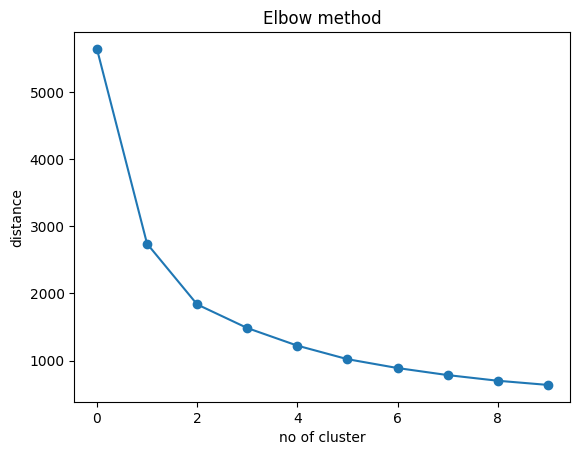

In [30]:
wcss=[]
for i in range(1,11):
    kmeans = KMeans(n_clusters = i,random_state = 42,n_init=10)
    kmeans.fit(X_Scaled)
    wcss.append(kmeans.inertia_)

plt.plot(wcss,marker="o")
plt.xlabel("no of cluster")
plt.ylabel("distance")
plt.title("Elbow method")
plt.show()
    

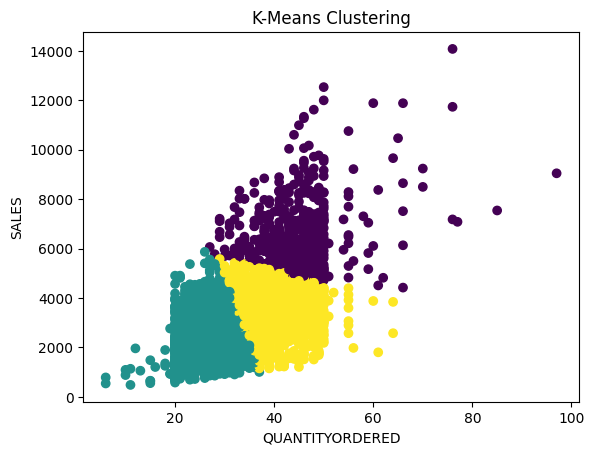

In [34]:
kmeans = KMeans(n_clusters = 3,random_state = 42,n_init=10)
df["kmeans_cluster"] = kmeans.fit_predict(X_Scaled) 
plt.scatter(X["QUANTITYORDERED"],X["SALES"],c=df["kmeans_cluster"])
plt.title("K-Means Clustering")
plt.xlabel("QUANTITYORDERED")
plt.ylabel("SALES")
plt.show()

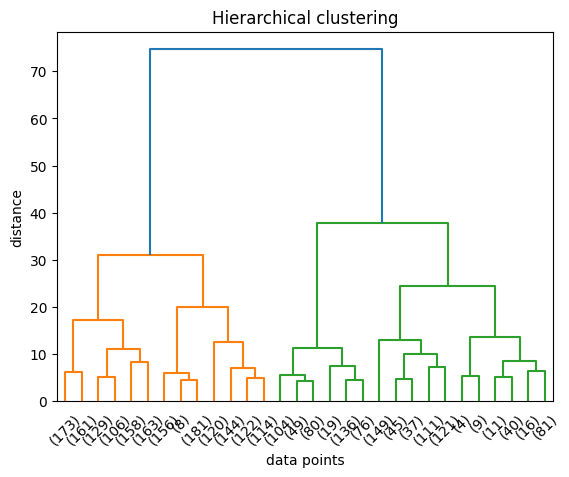

In [47]:
z = linkage(X_Scaled,method="ward")
plt.figure()
dendrogram(z,truncate_mode = "lastp",p=30)

plt.title("Hierarchical clustering")
plt.xlabel("data points")
plt.ylabel("distance")
plt.show()
